# Nhom9_CreditRisk — Báo cáo thực hành

**Mục tiêu:** phân loại khả năng vỡ nợ (`loan_status=1`) và đánh giá mô hình cây theo Average Precision (AP), không dùng Accuracy làm tiêu chí lựa chọn.

Case chính **Pre-Decision** chỉ dùng thông tin có tại lúc nhận hồ sơ. Case **Full-Feature** thêm `loan_grade` và `loan_int_rate` để minh họa rò rỉ hậu thẩm định. Notebook gọi các hàm trong `src/`; lần chạy đầu sẽ thực hiện toàn bộ pipeline, các lần sau đọc lại kết quả tái lập đã lưu.

## Phần 0 — Mục tiêu, giả định thời điểm và môi trường

In [ ]:
from pathlib import Pathade
import os, sys, json, platform
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
from src.config import *
from src.preprocessing import load_raw_data, clean_domain_outliers, split_train_test, build_preprocessor, build_model_pipeline
from src.pipeline import run_pipeline
from src.predict import predict_dataframe

if not (MODELS_DIR / 'final_model_pipeline.joblib').exists() or not (OUTPUTS_DIR / 'cv_results.csv').exists():
    run_pipeline()

import sklearn, matplotlib, seaborn
display(pd.DataFrame([{
    'Python': platform.python_version(), 'NumPy': np.__version__, 'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__, 'Matplotlib': matplotlib.__version__,
    'Seaborn': seaborn.__version__, 'Platform': platform.platform()
}], index=['Environment']).T.rename(columns={'Environment':'Version'}))
print('Bài toán: ước lượng xác suất vỡ nợ từ hồ sơ tại thời điểm trước quyết định.')

Bài toán: ước lượng xác suất vỡ nợ từ hồ sơ tại thời điểm trước quyết định.


,Version
Python,3.14.5
NumPy,2.4.5
pandas,2.3.3
scikit-learn,1.9.0
Matplotlib,3.10.9
Seaborn,0.13.2
Platform,Windows-11-10.0.26300-SP0


Decision Tree có thể biểu diễn quy tắc nhưng dễ phương sai cao; Random Forest lấy trung bình nhiều cây để giảm phương sai; Gradient Boosting cộng dồn cây nhỏ để giảm sai số tuần tự. Các mô hình cây chọn ngưỡng theo thứ tự giá trị nên không cần chuẩn hóa tuyến tính.

## Phần 1 — EDA và kiểm toán dữ liệu

Majority-class baseline trên CSV gốc: 78.18%
Duplicates: 165; tuổi >100: 5; employment >60: 2
Giá trị thiếu person_emp_length sau cleaning: 887 / 32,409
Default rate — thiếu employment: 31.68%; có dữ liệu: 21.59%
Bằng chứng: default rate tăng mạnh theo grade; grade và interest rate xuất hiện sau thẩm định/định giá.
loan_percent_income lệch tối đa so với loan_amnt/person_income: 0.09338235294117647


(32581, 12)

,count
loan_status,
0,25473
1,7108


,n,default_rate,prior_default_share,mean_interest_rate
loan_grade,,,,
A,10777,9.96%,0.00%,7.33%
B,10451,16.28%,0.00%,11.00%
C,6458,20.73%,50.42%,13.46%
D,3626,59.05%,51.74%,15.36%
E,964,64.42%,48.24%,17.01%
F,241,70.54%,46.47%,18.61%
G,64,98.44%,56.25%,20.25%


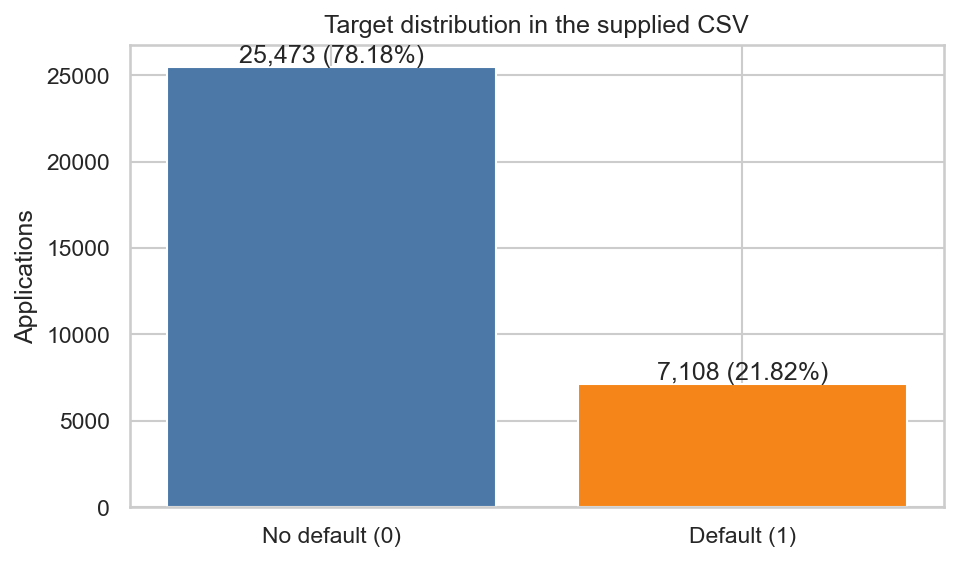

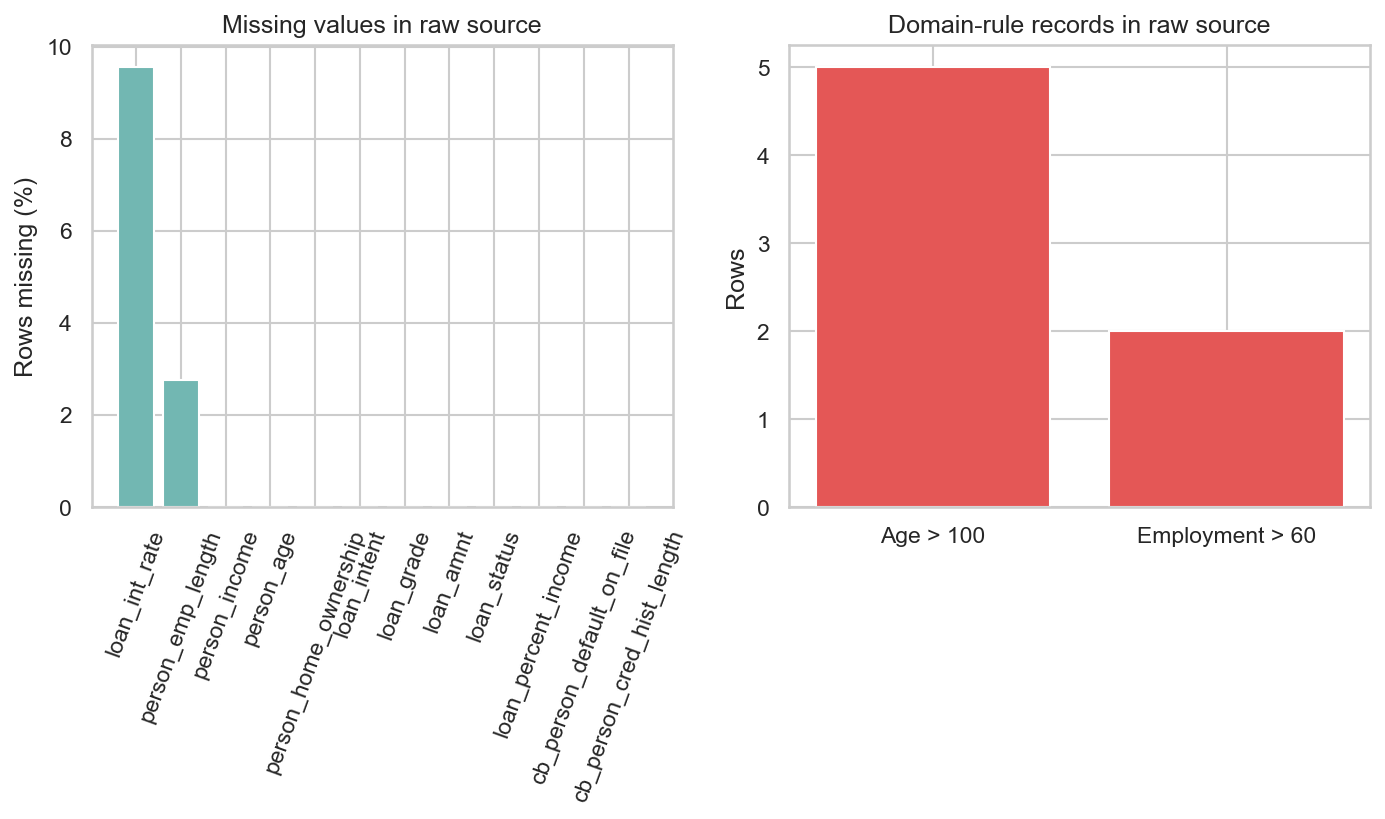

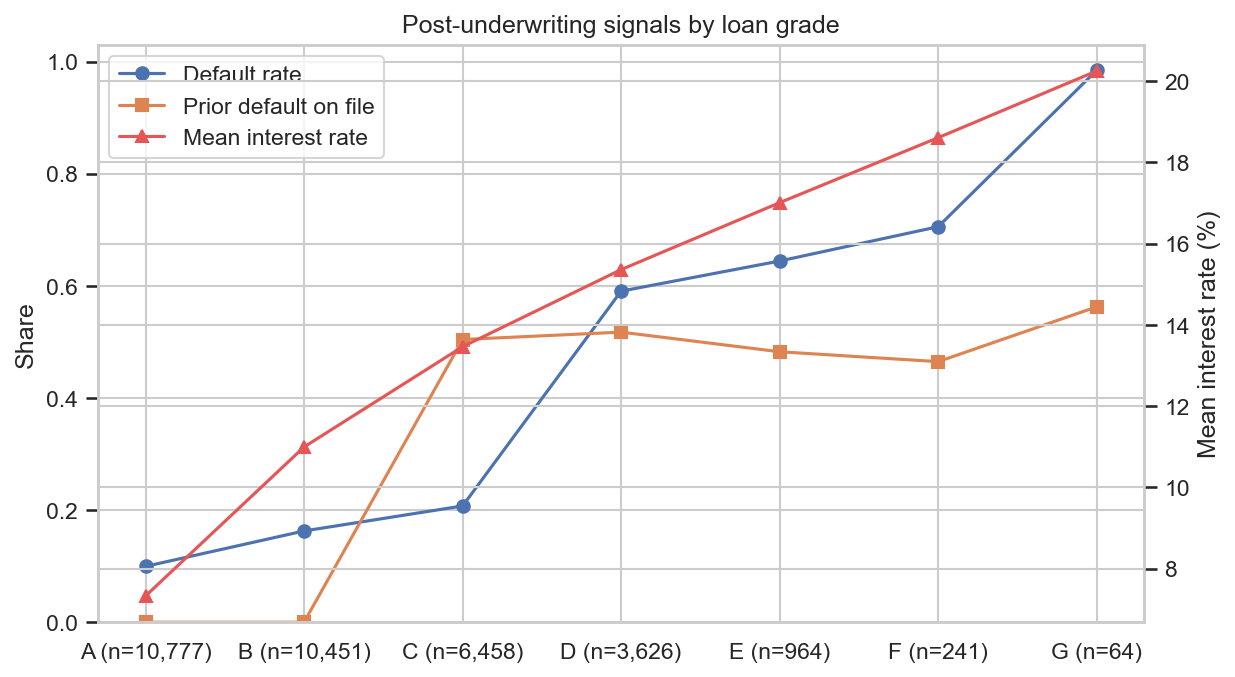

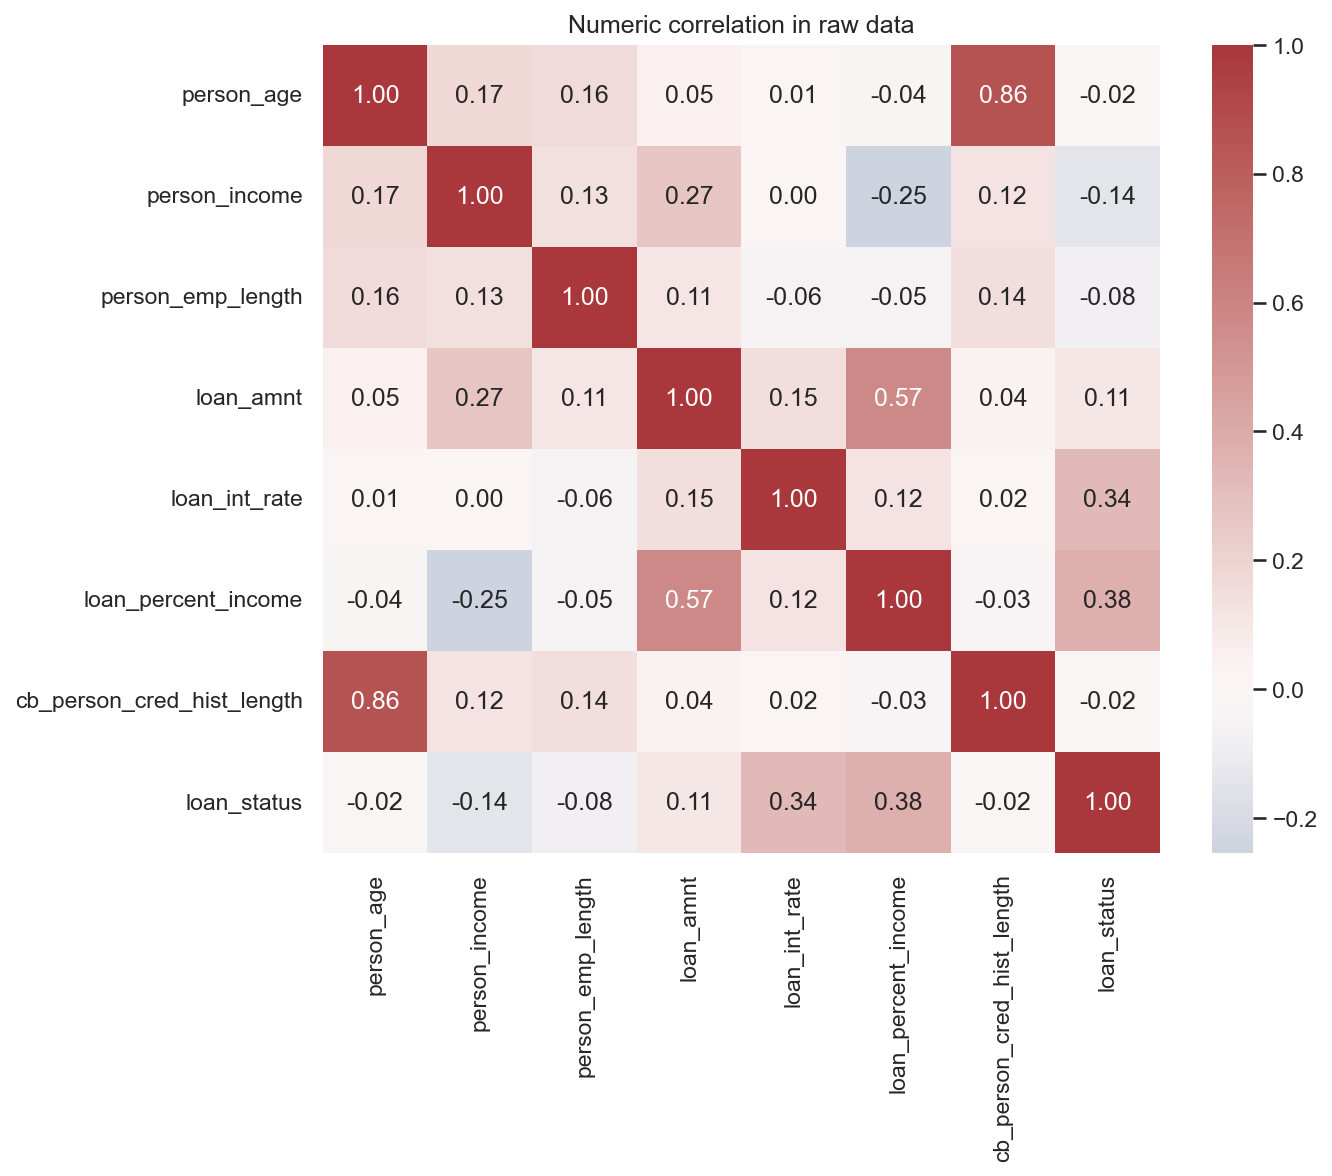

In [2]:
raw = load_raw_data()
cleaned = clean_domain_outliers(raw)
display(raw.shape, raw['loan_status'].value_counts().rename('count').to_frame())
print(f"Majority-class baseline trên CSV gốc: {max(raw.loan_status.mean(), 1-raw.loan_status.mean()):.2%}")
print(f"Duplicates: {raw.duplicated().sum():,}; tuổi >100: {(raw.person_age>100).sum():,}; employment >60: {(raw.person_emp_length>60).sum():,}")
print(f"Giá trị thiếu person_emp_length sau cleaning: {cleaned.person_emp_length.isna().sum():,} / {len(cleaned):,}")
miss_rate = cleaned.loc[cleaned.person_emp_length.isna(), 'loan_status'].mean()
present_rate = cleaned.loc[cleaned.person_emp_length.notna(), 'loan_status'].mean()
print(f"Default rate — thiếu employment: {miss_rate:.2%}; có dữ liệu: {present_rate:.2%}")
grade_audit = raw.groupby('loan_grade', observed=True).agg(
    n=('loan_status','size'), default_rate=('loan_status','mean'),
    prior_default_share=('cb_person_default_on_file', lambda s:(s=='Y').mean()),
    mean_interest_rate=('loan_int_rate','mean'))
display(grade_audit.style.format({'default_rate':'{:.2%}','prior_default_share':'{:.2%}','mean_interest_rate':'{:.2f}%'}))
print('Bằng chứng: default rate tăng mạnh theo grade; grade và interest rate xuất hiện sau thẩm định/định giá.')
print('loan_percent_income lệch tối đa so với loan_amnt/person_income:',
      (raw.loan_percent_income - raw.loan_amnt/raw.person_income).abs().max())
for f in ['1_eda_target_distribution.png','1_eda_missing_and_outliers.png','1_eda_grade_leakage_analysis.png','1_eda_correlation_heatmap.png']:
    display(Image(filename=str(IMAGES_DIR / f)))

**Kiểm toán số liệu:** bản mô tả kèm theo ghi 889 giá trị thiếu employment sau lọc; CSV thực tế còn 887. Sau khi loại trùng và áp dụng chính xác hai điều kiện miền, dữ liệu còn 32.409 dòng. Báo cáo sử dụng số đo trực tiếp từ archive.

## Phần 2 — Làm sạch, chia tập và cấu trúc pipeline

In [3]:
X_train, X_test, y_train, y_test = split_train_test(cleaned, 'B')
X_train_a, X_test_a, y_train_a, y_test_a = split_train_test(cleaned, 'A')
assert len(cleaned) == 32409
assert (X_train.shape, X_test.shape) == ((25927, 9), (6482, 9))
assert 'loan_status' not in X_train and 'loan_grade' not in X_train and 'loan_int_rate' not in X_train
assert X_train.index.intersection(X_test.index).empty
print('Train/test:', X_train.shape, X_test.shape, '| default rates:', round(y_train.mean(),4), round(y_test.mean(),4))
print(build_model_pipeline(__import__('sklearn.tree').tree.DecisionTreeClassifier(max_depth=3), 'B'))
preprocessor = build_preprocessor('B')
Xt_train = preprocessor.fit_transform(X_train)
assert not np.isnan(Xt_train).any()
print('Transformed train:', Xt_train.shape, '| indicators:', [n for n in preprocessor.get_feature_names_out() if 'missingindicator' in n])
print('Không dùng scaler: phép co giãn đơn điệu dương không đổi thứ tự và các ngưỡng ứng viên của cây.')

Train/test: (25927, 9) (6482, 9) | default rates: 0.2187 0.2188
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median'),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('nominal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),


## Phần 3 — Baseline và class imbalance

Các kết quả dùng 5-fold Stratified CV trên train; weighting được tính riêng trong từng fold.


,model,weighting,scenario,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std,Accuracy_mean,Accuracy_std
0,GradientBoosting,Unweighted,B,0.7873,0.0059,0.8790,0.0037,0.6515,0.0097,0.9535,0.0228,0.4951,0.0125,0.8842,0.0028
1,GradientBoosting,Balanced,B,0.7844,0.0063,0.8783,0.0043,0.6547,0.0093,0.6080,0.0143,0.7093,0.0046,0.8363,0.0063
2,RandomForest,Unweighted,B,0.7701,0.0038,0.8649,0.0023,0.6629,0.0115,0.8862,0.0146,0.5296,0.0125,0.8822,0.0036
3,RandomForest,Balanced,B,0.7684,0.0035,0.8651,0.0017,0.6698,0.0078,0.7414,0.0147,0.6109,0.0116,0.8682,0.0036
4,DecisionTree,Balanced,B,0.4734,0.0110,0.7596,0.0047,0.6250,0.0093,0.6273,0.0166,0.6229,0.0052,0.8365,0.0059
5,DecisionTree,Unweighted,B,0.4687,0.0123,0.7616,0.0075,0.6236,0.0116,0.6113,0.0149,0.6367,0.0135,0.8319,0.0061


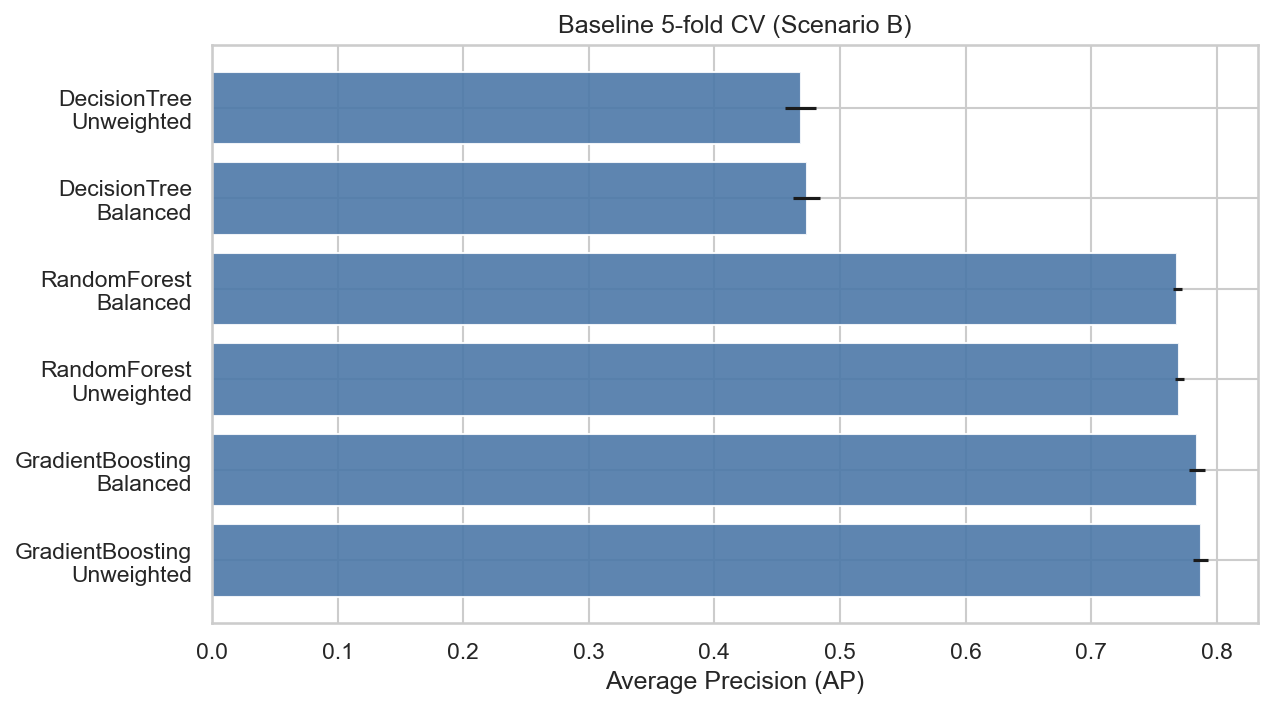

In [4]:
baseline = pd.read_csv(OUTPUTS_DIR / 'baseline_results.csv')
display(baseline.round(4))
display(Image(filename=str(IMAGES_DIR / '3_baseline_cv_comparison.png')))
print('Các kết quả dùng 5-fold Stratified CV trên train; weighting được tính riêng trong từng fold.')

## Phần 4 — Tuning và chọn mô hình theo AP

Chọn theo Average Precision (AP) = sklearn.metrics.average_precision_score: GradientBoosting


,model,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,F1_mean,F1_std,Precision_mean,Recall_mean
0,GradientBoosting,0.8228,0.0085,0.9069,0.0069,0.7032,0.0046,0.6637,0.7478
1,RandomForest,0.7889,0.0057,0.8805,0.0033,0.6782,0.0076,0.6673,0.6896
2,DecisionTree,0.7611,0.0075,0.8561,0.0049,0.6293,0.0197,0.5583,0.7226


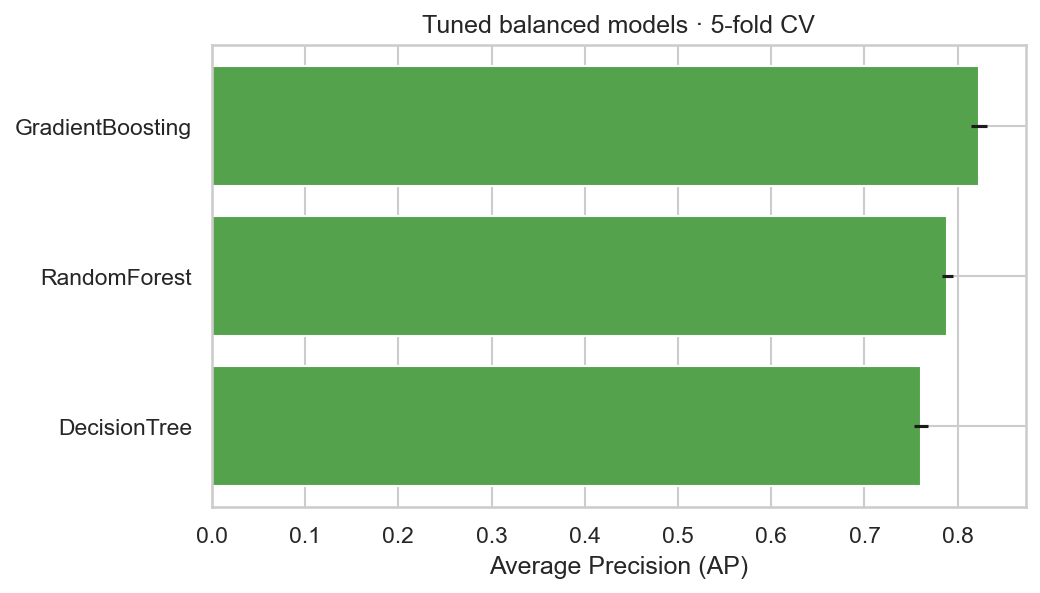

In [5]:
cv_results = pd.read_csv(OUTPUTS_DIR / 'cv_results.csv')
display(cv_results[['model','AP_mean','AP_std','ROC_AUC_mean','ROC_AUC_std','F1_mean','F1_std','Precision_mean','Recall_mean']].round(4))
best_row = cv_results.sort_values('AP_mean', ascending=False).iloc[0]
print('Chọn theo Average Precision (AP) = sklearn.metrics.average_precision_score:', best_row['model'])
display(Image(filename=str(IMAGES_DIR / '4_tuned_cv_comparison.png')))

## Phần 5 — Chọn threshold bằng xác suất OOF

t_opt=0.62 (F1 tối đa trên OOF); t_recall70=0.56 (ngưỡng cao nhất với OOF Recall ≥ 0.70)


,threshold,ap,roc_auc,f1,precision,recall,accuracy,tn,fp,fn,tp,selected_for_f1,selected_for_recall70
51,0.56,0.822626,0.906812,0.712052,0.721528,0.702822,0.875689,18719,1538,1685,3985,False,True
57,0.62,0.822626,0.906812,0.716245,0.778353,0.663316,0.885062,19186,1071,1909,3761,True,False


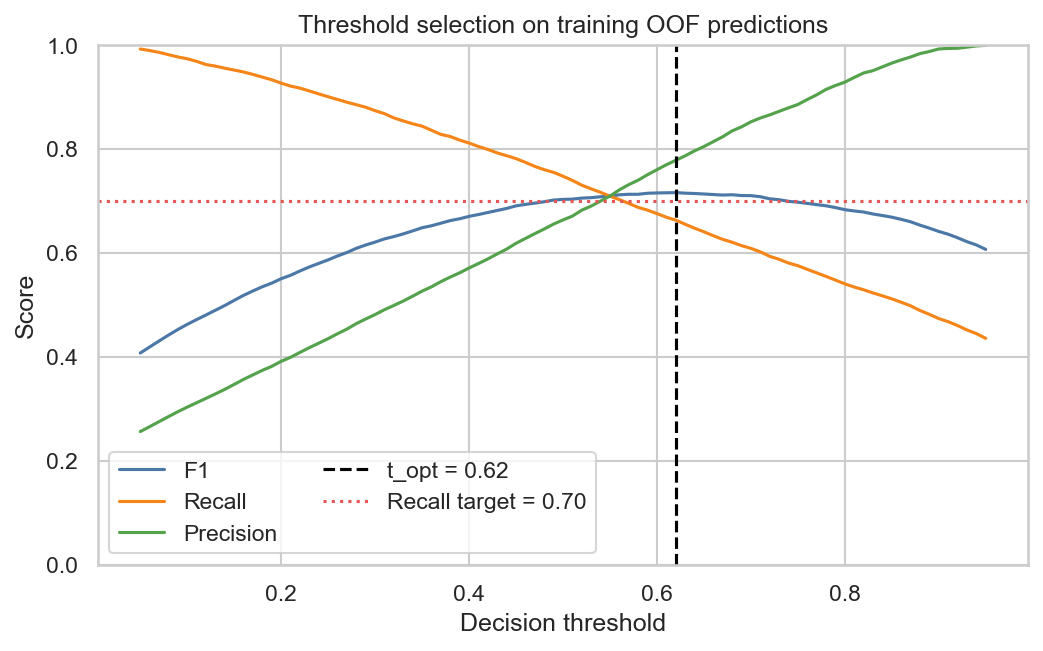

In [6]:
thresholds = pd.read_csv(OUTPUTS_DIR / 'threshold_analysis.csv')
meta = json.loads((MODELS_DIR / 'model_metadata.json').read_text(encoding='utf-8'))
t_opt, t_recall70 = meta['optimal_threshold'], meta['recall_70_threshold']
display(thresholds[thresholds.selected_for_f1 | thresholds.selected_for_recall70])
print(f't_opt={t_opt:.2f} (F1 tối đa trên OOF); t_recall70={t_recall70:.2f} (ngưỡng cao nhất với OOF Recall ≥ 0.70)')
display(Image(filename=str(IMAGES_DIR / '5_threshold_optimization.png')))

## Phần 6 — Đánh giá test cuối và so sánh feature scenarios

Accuracy chỉ đọc cùng majority-class baseline; mô hình được chọn theo AP.


,model,scenario,evaluation,threshold,ap,roc_auc,f1,precision,recall,accuracy,tn,fp,fn,tp
0,GradientBoosting,B,default_0.50,0.50,0.8355,0.9167,0.7136,0.6581,0.7793,0.8632,4490,574,313,1105
1,GradientBoosting,B,oof_t_opt,0.62,0.8355,0.9167,0.7253,0.7727,0.6834,0.8868,4779,285,449,969


,scenario,scenario_name,oof_t_opt,evaluation,threshold,ap,roc_auc,f1,precision,recall,accuracy,tn,fp,fn,tp
0,B,Pre-Decision,0.62,default_0.50,0.50,0.8355,0.9167,0.7136,0.6581,0.7793,0.8632,4490,574,313,1105
1,B,Pre-Decision,0.62,oof_t_opt,0.62,0.8355,0.9167,0.7253,0.7727,0.6834,0.8868,4779,285,449,969
2,A,Full-Feature (leakage comparison),0.64,default_0.50,0.50,0.9152,0.9549,0.8254,0.8292,0.8216,0.9239,4824,240,253,1165
3,A,Full-Feature (leakage comparison),0.64,oof_t_opt,0.64,0.9152,0.9549,0.8443,0.9281,0.7743,0.9375,4979,85,320,1098


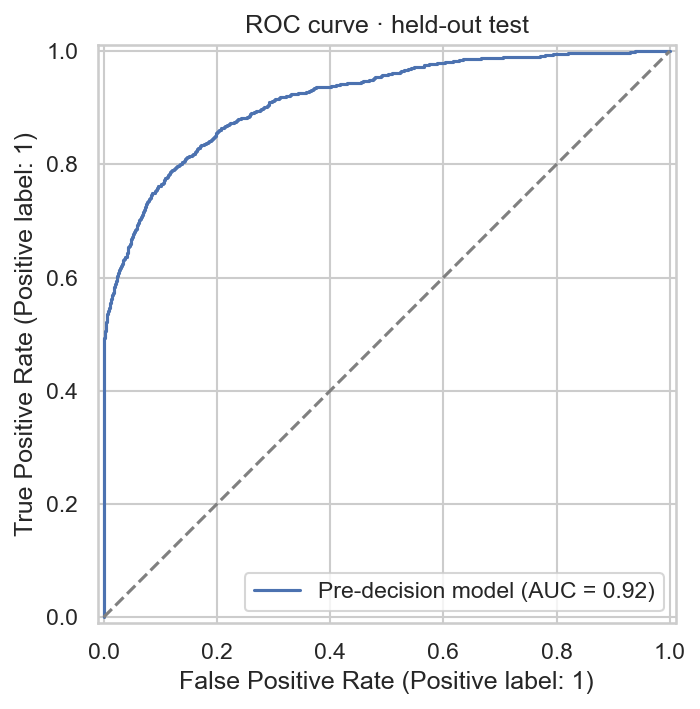

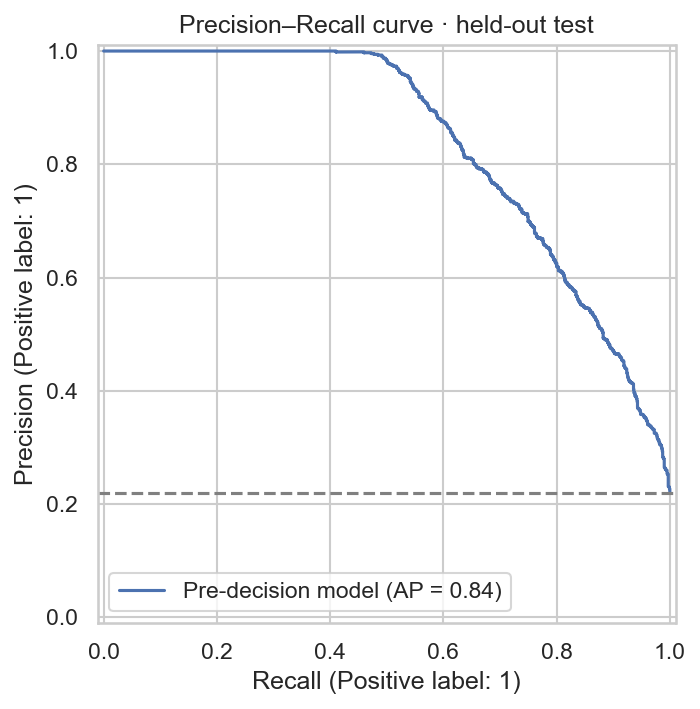

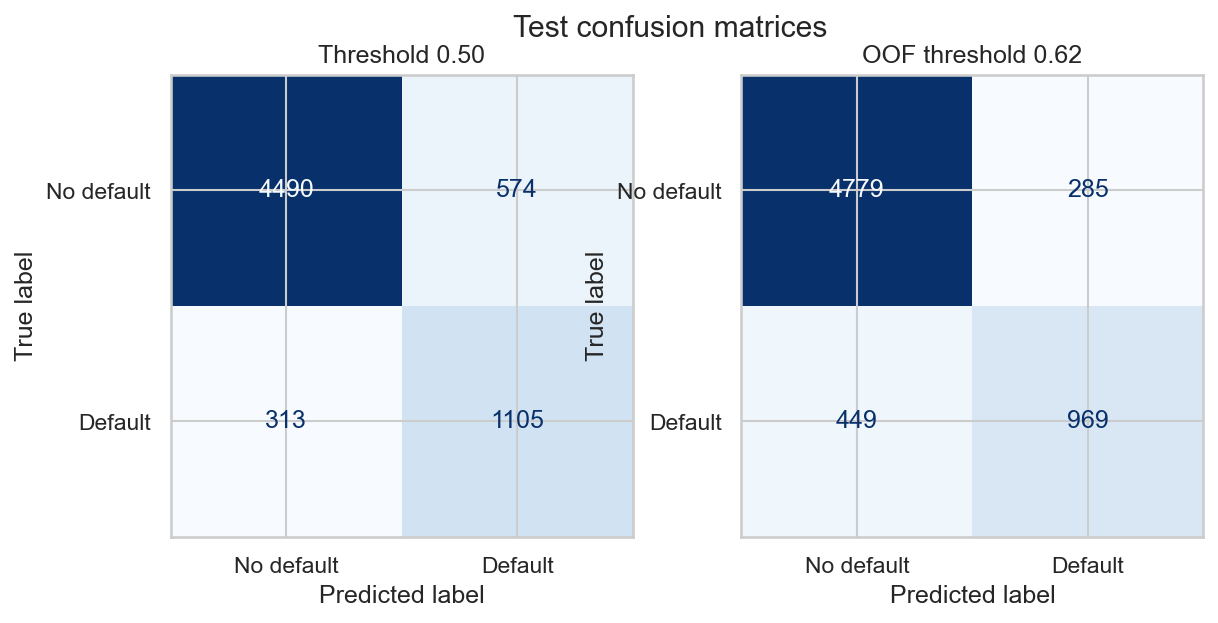

In [7]:
test_results = pd.read_csv(OUTPUTS_DIR / 'test_results.csv')
comparison = pd.read_csv(OUTPUTS_DIR / 'scenario_comparison.csv')
display(test_results.round(4))
display(comparison.round(4))
print('Accuracy chỉ đọc cùng majority-class baseline; mô hình được chọn theo AP.')
for f in ['6_roc_curves.png','6_pr_curves.png','6_confusion_matrices.png']:
    display(Image(filename=str(IMAGES_DIR / f)))

## Phần 7 — Bias–variance, giải thích mô hình và toán học from-scratch

Gradient boosting max absolute difference: 1.1102230246251565e-16
Feature importance mô tả phụ thuộc của mô hình; không hàm ý quan hệ nhân quả. Biến tương quan có thể chia sẻ importance.


,feature,built_in_impurity_importance,permutation_ap_mean,permutation_ap_std
0,person_income,0.32689,0.33175,0.00619
1,loan_percent_income,0.29187,0.31995,0.01151
2,person_home_ownership,0.10648,0.22625,0.00870
3,loan_amnt,0.04833,0.17813,0.00887
4,loan_intent,0.08118,0.09746,0.00426
5,cb_person_default_on_file,0.07177,0.04506,0.00273
6,person_age,0.02870,0.03186,0.00220
7,person_emp_length,0.02903,0.02965,0.00122
8,cb_person_cred_hist_length,0.01481,0.01261,0.00087


,weighting,scratch_feature,scratch_threshold,scratch_information_gain,sklearn_feature,sklearn_threshold,sklearn_information_gain,absolute_gain_difference
0,unweighted,loan_percent_income,0.305,0.062918,loan_percent_income,0.305,0.062918,0.0
1,balanced,loan_percent_income,0.305,0.083781,loan_percent_income,0.305,0.083781,0.0


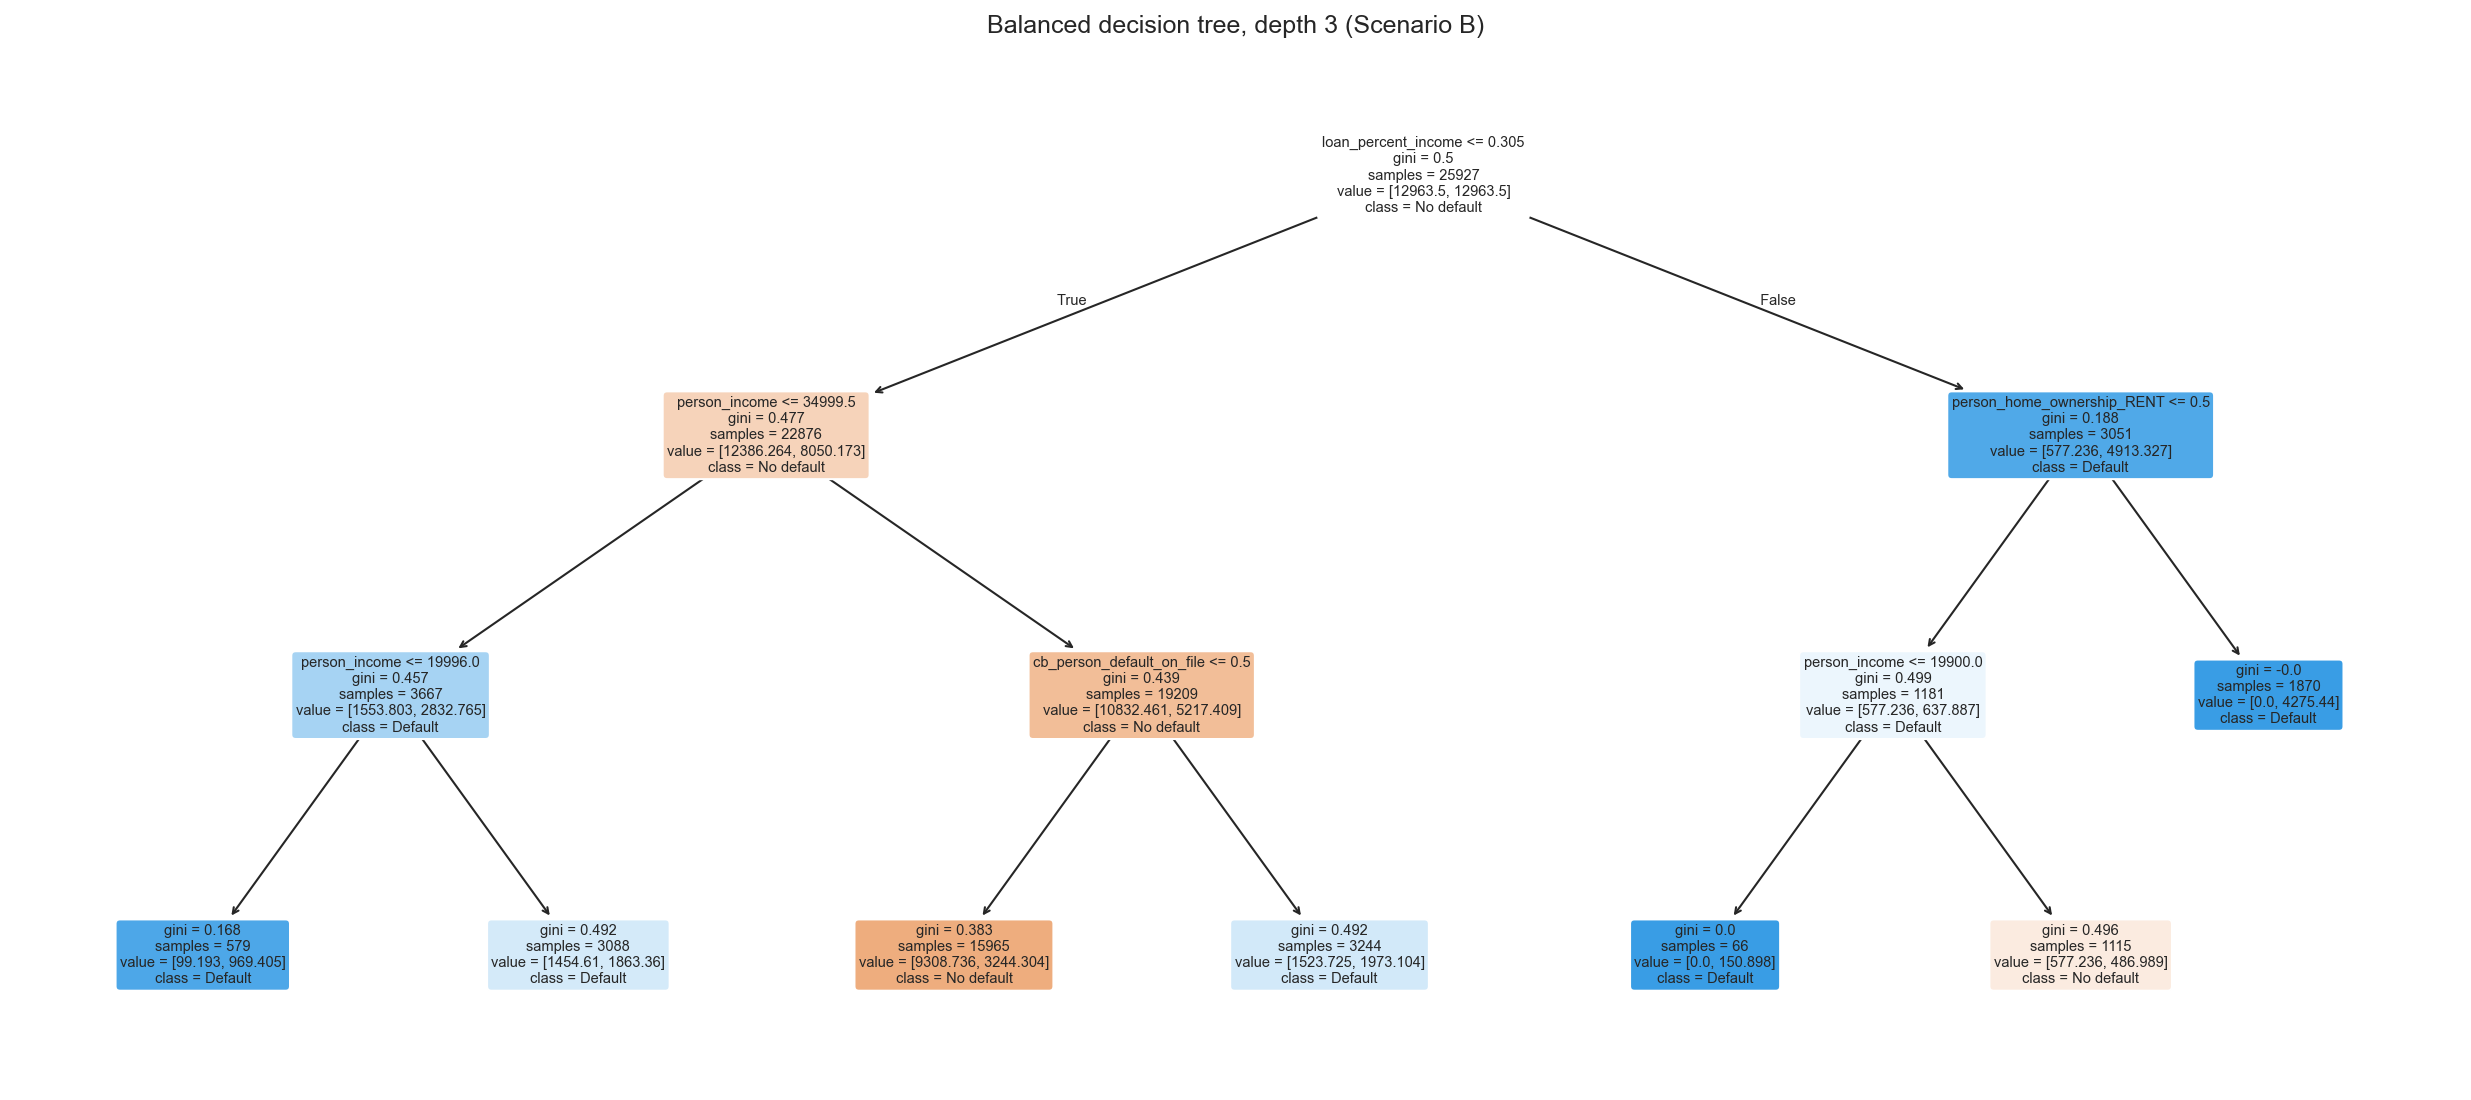

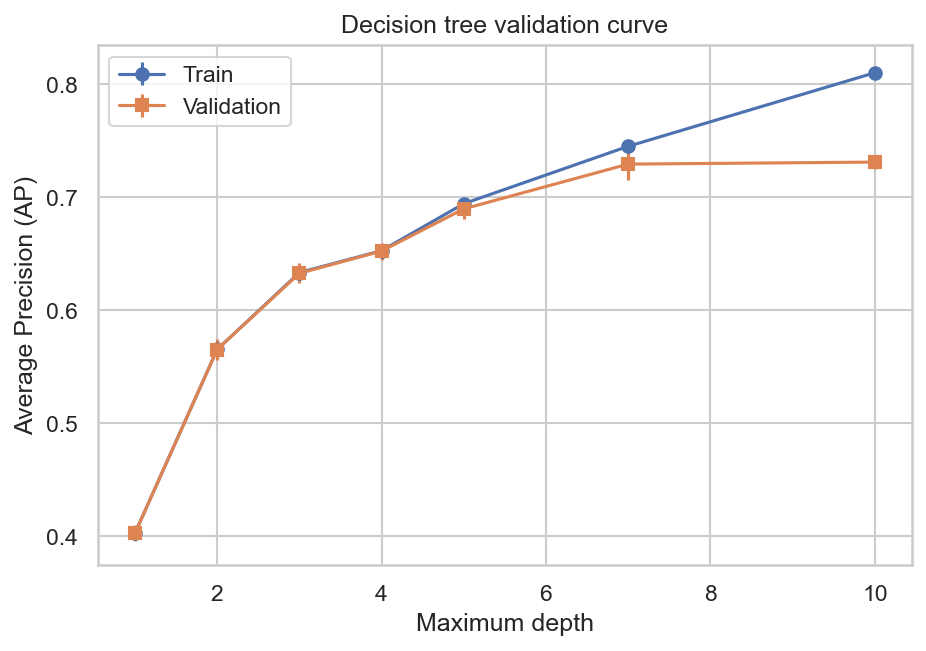

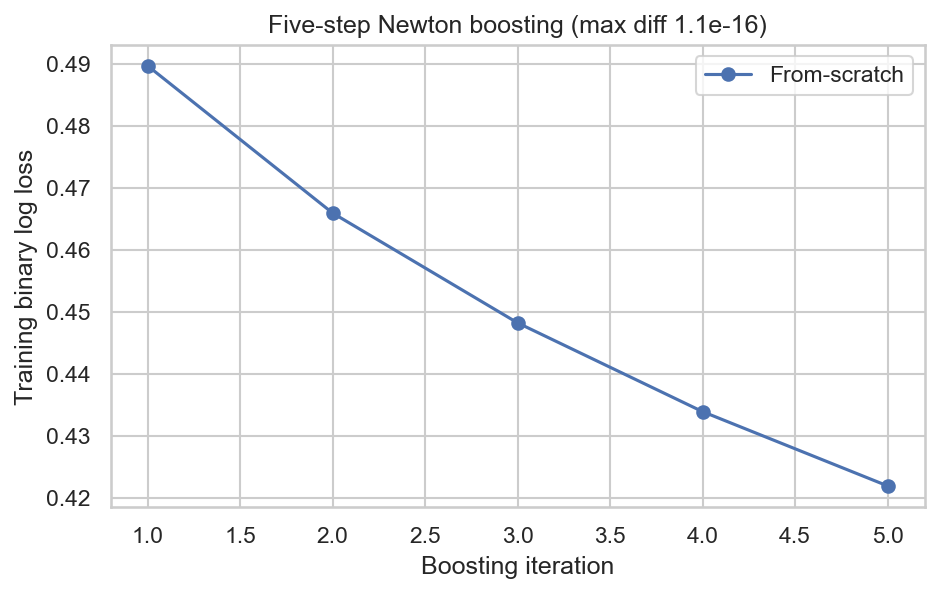

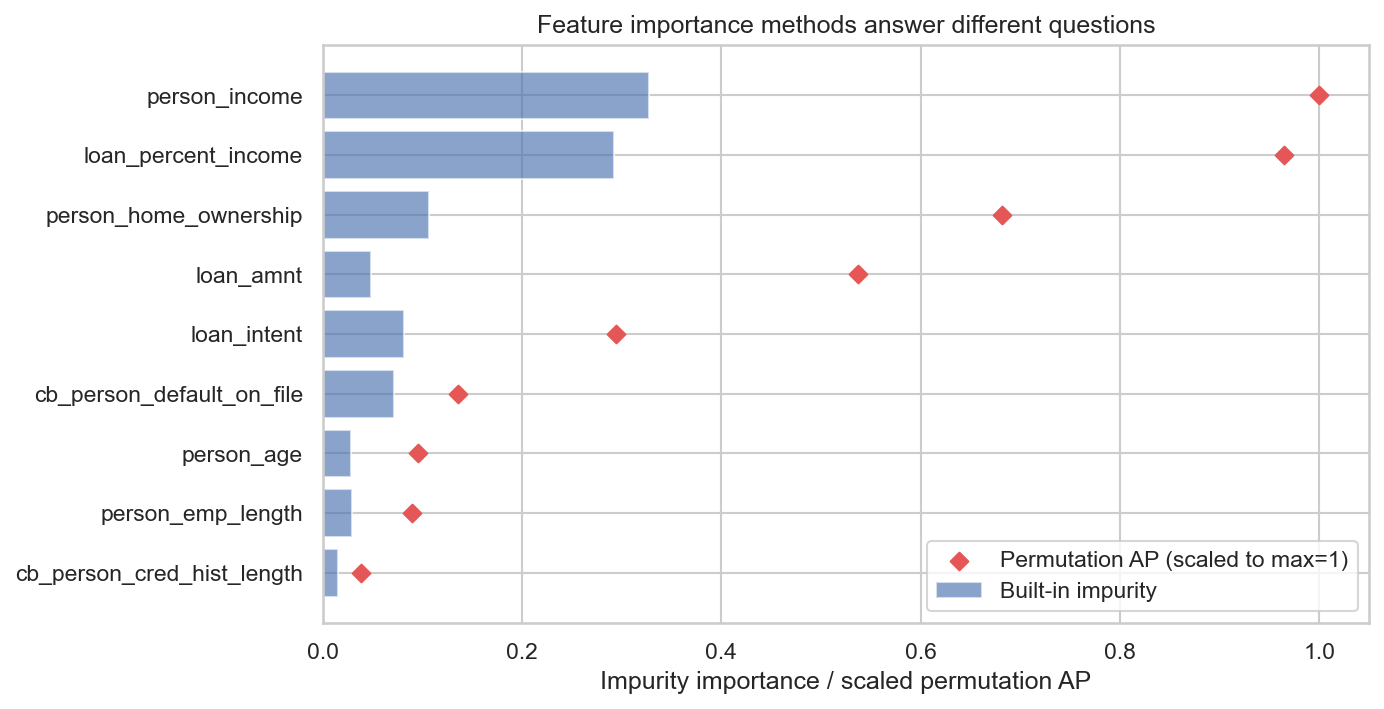

In [8]:
importance = pd.read_csv(OUTPUTS_DIR / 'feature_importance.csv')
gini = pd.read_csv(OUTPUTS_DIR / 'gini_scratch_verification.csv')
scratch = json.loads((OUTPUTS_DIR / 'scratch_boosting_verification.json').read_text(encoding='utf-8'))
display(importance.round(5))
display(gini.round(10))
print('Gradient boosting max absolute difference:', scratch['max_abs_diff'])
for f in ['7_dt_tree_structure.png','7_validation_curve_bias_variance.png','7_boosting_from_scratch.png','7_feature_importance_comparison.png']:
    display(Image(filename=str(IMAGES_DIR / f)))
print('Feature importance mô tả phụ thuộc của mô hình; không hàm ý quan hệ nhân quả. Biến tương quan có thể chia sẻ importance.')

## Phần 8 — Artifact, inference demo và khuyến nghị

In [9]:
demo = pd.DataFrame([
    [29, 60000, 4.0, 12000, 0.20, 6, 'RENT', 'EDUCATION', 'N'],
    [42, 95000, 12.0, 18000, 0.19, 14, 'MORTGAGE', 'HOMEIMPROVEMENT', 'N'],
    [24, 38000, 2.0, 10000, 0.26, 4, 'RENT', 'MEDICAL', 'Y'],
    [35, 72000, 8.0, 15000, 0.21, 9, 'OWN', 'PERSONAL', 'N'],
    [51, 110000, 20.0, 25000, 0.23, 23, 'MORTGAGE', 'VENTURE', 'Y'],
], columns=SCENARIO_FEATURES['B'])
predictions = predict_dataframe(demo)
display(predictions[['person_age','person_income','loan_intent','default_probability','predicted_default','risk_level']].round(4))
print('Artifact:', MODELS_DIR / 'final_model_pipeline.joblib')
print('Metadata:', MODELS_DIR / 'model_metadata.json')
print('Khuyến nghị: kiểm định theo thời gian và hiệu chỉnh xác suất trước khi dùng nghiệp vụ; theo dõi recall, precision, calibration và drift; chỉ dùng Scenario B khi cần dự đoán trước thẩm định.')

Artifact: C:\Users\tptha\Documents\Codex\2026-11-19\files-mentioned-by-the-user-credit\outputs\Nhom9_CreditRisk\models\final_model_pipeline.joblib
Metadata: C:\Users\tptha\Documents\Codex\2026-11-19\files-mentioned-by-the-user-credit\outputs\Nhom9_CreditRisk\models\model_metadata.json
Khuyến nghị: kiểm định theo thời gian và hiệu chỉnh xác suất trước khi dùng nghiệp vụ; theo dõi recall, precision, calibration và drift; chỉ dùng Scenario B khi cần dự đoán trước thẩm định.


,person_age,person_income,loan_intent,default_probability,predicted_default,risk_level
0,29,60000,EDUCATION,0.0648,0,LOW
1,42,95000,HOMEIMPROVEMENT,0.0370,0,LOW
2,24,38000,MEDICAL,0.6318,1,HIGH
3,35,72000,PERSONAL,0.0182,0,LOW
4,51,110000,VENTURE,0.2632,0,MEDIUM
